# Phase 3b — Locking the physics result, and what it buys

Phase 3a found, on the LLPSense feature basis:

| | concentration violations | ROC-AUC (A / B / C*) |
|---|---|---|
| unconstrained | **6.2%** | 0.834 / 0.783 / 0.648 |
| physics-constrained | **0.0%** | 0.833 / 0.776 / 0.641 |

NaCl, left free in both, showed ~29% violations in both — so the metric detects
real non-monotonicity rather than always reading zero.

Two gaps remain.

**1. The accuracy comparison was unpaired.** Each variant was scored on its own
5 folds, so differences of 0.001-0.007 sit well inside the noise. Training both
variants on *identical* splits and testing the paired differences is far more
sensitive, and it is the right way to ask "does enforcing physics cost anything".

**2. The constraint buys something we have not yet used.** With concentration
monotonic, the predicted probability crosses any threshold exactly once, so the
**saturation concentration c_sat** is well defined. In the unconstrained model the
curve can wiggle and cross repeatedly, leaving c_sat ambiguous. c_sat is a directly
measurable quantity and the natural bridge to the coarse-grained simulations.

**Setup:** Runtime -> T4 GPU, ~45 min. Upload `llpsense_final_noseq.csv` and
`llpsense_t5.npz`.

## 1. Setup

In [ ]:
import numpy as np, pandas as pd, subprocess, time, json, warnings
warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
from scipy import stats
GPU = subprocess.run("nvidia-smi", shell=True, capture_output=True).returncode == 0
print("GPU:", GPU)

from google.colab import files
up = files.upload()

df  = pd.read_csv("llpsense_final_noseq.csv")
z   = np.load("llpsense_t5.npz", allow_pickle=True)
emb = pd.DataFrame(z["X"], index=z["SeqID"])
COND = ['Conc','pH','temp','MgCl2','NaCl','KCl','PEG300-1k','PEG3k-6k','PEG8k-20k',
        'Ficoll','Dextran -40','Dextran 70-','Glycerol']
X = np.hstack([emb.loc[df.SeqID].to_numpy(np.float32), df[COND].to_numpy(np.float32)])
y, w = df.Label.to_numpy(), df.w_record.to_numpy()
N_EMB = emb.shape[1]; IDX = {c: N_EMB+i for i,c in enumerate(COND)}

UP = ['Conc','PEG300-1k','PEG3k-6k','PEG8k-20k','Ficoll','Dextran -40','Dextran 70-']
MONO = tuple([0]*N_EMB + [1 if c in UP else 0 for c in COND])

HP = dict(n_estimators=877, max_depth=14, learning_rate=0.023722174554030036,
          min_child_weight=2, colsample_bytree=0.5655509178160505,
          subsample=0.5482175662874387, gamma=0.0012682360748828933,
          reg_lambda=0.3024802937837069, reg_alpha=0.04238171400820899, random_state=42)
RUNTIME = dict(tree_method="hist", eval_metric="logloss",
               **({"device":"cuda"} if GPU else {"n_jobs":-1}))
print("ready:", X.shape)

GPU: True


Saving llpsense_final_noseq.csv to llpsense_final_noseq.csv
Saving llpsense_t5.npz to llpsense_t5.npz
ready: (50557, 1037)


## 2. Paired comparison — does physics cost accuracy?

Both variants are trained on the **same** train/test split each time, so the
difference can be tested fold by fold. 2 seeds x 5 folds = 10 paired differences
per regime.

In [ ]:
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import roc_auc_score, brier_score_loss
from xgboost import XGBClassifier

REGIMES = [("A  new condition, known protein","RecordID"),
           ("B  new protein","SeqID"),
           ("C* new family (hardened)","GroupX")]
SEEDS = [1, 2]
paired = {}

for rname, key in REGIMES:
    g, du, dc, t0 = df[key].to_numpy(), [], [], time.time()
    for s in SEEDS:
        for i, j in StratifiedGroupKFold(5, shuffle=True, random_state=s).split(X, y, groups=g):
            if len(np.unique(y[j])) < 2: continue
            scores = []
            for kw in ({}, {"monotone_constraints": MONO}):
                m = XGBClassifier(**HP, **kw, **RUNTIME)
                m.fit(X[i], y[i], sample_weight=w[i])
                p = m.predict_proba(X[j])[:, 1]
                scores.append(roc_auc_score(y[j], p, sample_weight=w[j]))
            du.append(scores[0]); dc.append(scores[1])
    du, dc = np.array(du), np.array(dc)
    d = dc - du
    t, p = stats.ttest_rel(dc, du)
    paired[rname] = dict(uncon=du.tolist(), con=dc.tolist())
    print(f"{rname:34s} uncon {du.mean():.3f}  constrained {dc.mean():.3f}  "
          f"paired diff {d.mean():+.4f} ± {d.std(ddof=1)/np.sqrt(len(d)):.4f}  "
          f"t {t:+.2f}  p {p:.3f}   ({time.time()-t0:.0f}s)", flush=True)
json.dump(paired, open("phase3b_paired.json","w"))

A  new condition, known protein    uncon 0.834  constrained 0.832  paired diff -0.0021 ± 0.0006  t -3.65  p 0.005   (590s)
B  new protein                     uncon 0.786  constrained 0.778  paired diff -0.0082 ± 0.0018  t -4.68  p 0.001   (590s)
C* new family (hardened)           uncon 0.651  constrained 0.644  paired diff -0.0063 ± 0.0059  t -1.08  p 0.310   (585s)


**Reading it:** a paired difference whose confidence interval straddles zero means
the constraint is free. A small but consistently negative difference is still a fine
result — quote the number and let the reader judge whether 0.005 ROC-AUC is worth
guaranteed physical consistency.

## 3. Does the model recover reentrant salt behaviour?

NaCl is unconstrained in both models, and showed ~29% "violations" — which for salt
is not an error at all. Many phase-separating proteins are **reentrant**: demixing is
suppressed at low salt, promoted at intermediate salt, suppressed again at high salt.
If the model reproduces that hump without being told to, it has learned real physics
rather than curve-fitting.

In [ ]:
full_c = XGBClassifier(**HP, monotone_constraints=MONO, **RUNTIME)
full_c.fit(X, y, sample_weight=w)

# one representative condition row per sequence
rep = df.groupby("SeqID").head(1).index.to_numpy()
Xr  = X[rep].copy()
names = df.loc[rep, "ProteinName"].to_numpy()

grid = np.linspace(0, 1, 25)            # normalised NaCl, 0-2000 mM
curves = np.zeros((len(Xr), len(grid)))
for k, v in enumerate(grid):
    Xt = Xr.copy(); Xt[:, IDX['NaCl']] = v
    curves[:, k] = full_c.predict_proba(Xt)[:, 1]

rise = curves.argmax(1)
shape = np.where((rise > 1) & (rise < len(grid)-2), "reentrant (interior peak)",
         np.where(rise <= 1, "monotonic decreasing", "monotonic increasing"))
print(pd.Series(shape).value_counts().to_string())
print(f"\nmedian peak position: {grid[int(np.median(rise))]*2000:.0f} mM NaCl")

monotonic decreasing         531
reentrant (interior peak)    323

median peak position: 83 mM NaCl


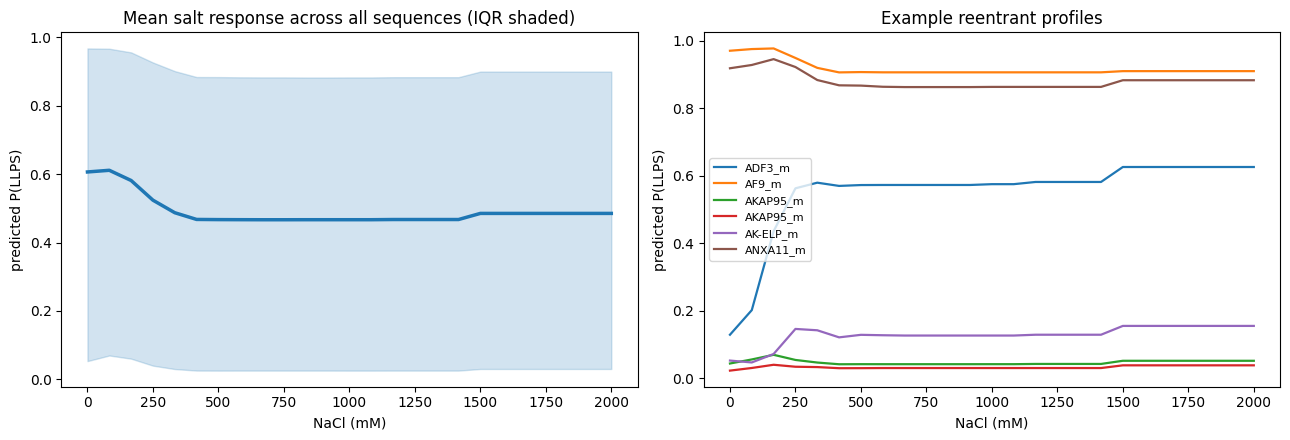

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].plot(grid*2000, curves.mean(0), lw=2.5, color="C0")
ax[0].fill_between(grid*2000, np.percentile(curves,25,axis=0),
                   np.percentile(curves,75,axis=0), alpha=.2, color="C0")
ax[0].set(xlabel="NaCl (mM)", ylabel="predicted P(LLPS)",
          title="Mean salt response across all sequences (IQR shaded)")

sel = np.where(shape == "reentrant (interior peak)")[0][:6]
for s in sel:
    ax[1].plot(grid*2000, curves[s], lw=1.6, label=str(names[s])[:16])
ax[1].set(xlabel="NaCl (mM)", ylabel="predicted P(LLPS)", title="Example reentrant profiles")
ax[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig("salt_reentrance.png", dpi=150); plt.show()

## 4. Saturation concentration — what monotonicity buys

With concentration constrained, P(LLPS) rises monotonically, so the crossing of
P = 0.5 is unique and **c_sat** is well defined. Without the constraint the curve can
cross several times. This quantifies how often that ambiguity actually arises.

number of P=0.5 crossings as concentration rises:
  unconstrained          {0: np.int64(445), 1: np.int64(403), 2: np.int64(2), 3: np.int64(4)}   ambiguous (>1 crossing): 0.7%
  physics-constrained    {0: np.int64(385), 1: np.int64(469)}   ambiguous (>1 crossing): 0.0%

c_sat defined for 623/854 sequences (73%); median 26 uM


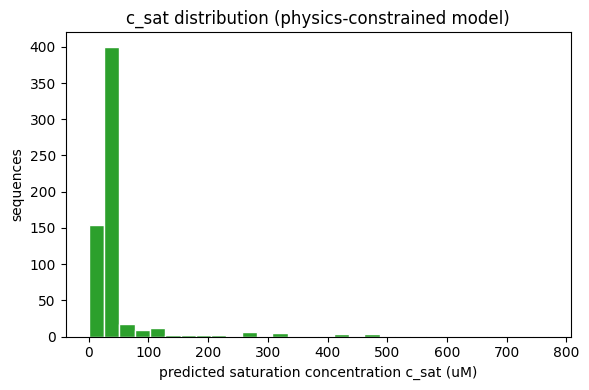

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
full_u = XGBClassifier(**HP, **RUNTIME); full_u.fit(X, y, sample_weight=w)
cgrid = np.linspace(0, 1, 40)

def crossings(model):
    P = np.zeros((len(Xr), len(cgrid)))
    for k, v in enumerate(cgrid):
        Xt = Xr.copy(); Xt[:, IDX['Conc']] = v
        P[:, k] = model.predict_proba(Xt)[:, 1]
    sign = (P > 0.5).astype(int)
    ncross = np.abs(np.diff(sign, axis=1)).sum(1)
    return P, ncross

Pu, nu = crossings(full_u)
Pc, nc = crossings(full_c)
print("number of P=0.5 crossings as concentration rises:")
for lab, n in [("unconstrained", nu), ("physics-constrained", nc)]:
    vc = pd.Series(n).value_counts().sort_index()
    amb = (n > 1).mean()
    print(f"  {lab:22s} {dict(vc)}   ambiguous (>1 crossing): {100*amb:.1f}%")

csat = np.full(len(Xr), np.nan)
for i in range(len(Xr)):
    idx = np.where(Pc[i] > 0.5)[0]
    if len(idx): csat[i] = cgrid[idx[0]] * 1000     # uM
ok = np.isfinite(csat)
print(f"\nc_sat defined for {ok.sum()}/{len(csat)} sequences "
      f"({100*ok.mean():.0f}%); median {np.nanmedian(csat):.0f} uM")

plt.figure(figsize=(6,4))
plt.hist(csat[ok], bins=30, color="C2", edgecolor="w")
plt.xlabel("predicted saturation concentration c_sat (uM)"); plt.ylabel("sequences")
plt.title("c_sat distribution (physics-constrained model)")
plt.tight_layout(); plt.savefig("csat_distribution.png", dpi=150); plt.show()

pd.DataFrame({"SeqID": df.loc[rep,"SeqID"].to_numpy(), "ProteinName": names,
              "c_sat_uM": csat, "salt_shape": shape}).to_csv("csat_predictions.csv", index=False)
from google.colab import files
files.download("phase3b_paired.json"); files.download("csat_predictions.csv")
files.download("salt_reentrance.png"); files.download("csat_distribution.png")

### Why c_sat matters for the rest of the project

c_sat is measurable in the lab and computable from a coarse-grained simulation, so it
is the quantity that lets the model, the database and the simulations be compared on
the same axis. For Phase 4, pick simulation targets by predicted c_sat — a few with
low c_sat, a few with high — rather than by raw classification probability. That is a
sharper test than "does it phase separate", and it is only well posed because the
model is monotonic.